# Hard DFE mixer and channel filter
Connect DAC0 (J44) to ADC0 (J36). The LMK supplies a 250 MHz reference. The RFDC samples at 2.5 GS/s and decimates by eight. Each capture contains 1,024 complex samples at 312.5 MS/s. The DAC uses the fixed 20 mA configuration. Run with exclusive access to the board. See the overlay README for installation.

In [1]:
from pathlib import Path
import os, json
import numpy as np
import matplotlib.pyplot as plt
from dfe_mixer_ccf import MixerCCFOverlay, FS, N, TONES, spectrum

bit = Path(os.getenv("DFE_BITFILE", "dfe_mixer_ccf.bit"))
manifest = Path(os.getenv("DFE_MANIFEST", "artifacts.sha256"))
out = Path(os.getenv("DFE_OUTPUT", "."))
out.mkdir(exist_ok=True)
offsets = (4.8828125, -7.32421875, 9.765625, 4.8828125)
captures, result = {}, {}

## Acquire the raw and filtered streams
For each single-tone measurement, tune the NCO to leave a known signed baseband offset. In dual-tone mode keep the 39.0625 MHz line in band and measure the rejection of the simultaneous 117.1875 MHz line. Each pair of snapshots starts at an independent phase.

In [2]:
with MixerCCFOverlay.open(bit, manifest) as ol:
    result["current_uA"] = ol.current_ua
    result["taps_q15"] = ol.taps.tolist()
    for mode in range(4 if ol.selectable else 1):
        frequencies = TONES[mode]
        nco = frequencies[0] - offsets[mode]
        ol.tune(nco)
        ol.play(mode)
        try:
            raw, filtered = ol.capture(True), ol.capture(False)
            captures[mode] = raw, filtered
        finally:
            ol.stop_tone()
        print(f"Mode {mode}, DAC {frequencies} MHz, NCO {nco} MHz")
    result["aligned_trigger"] = ol.aligned
    result["blocks"] = ol.status()
    result["dac_status"] = ol.control.read(8) if ol.selectable else None
print(json.dumps(result, indent=2))

LMK04828: PLL2 locked with programmed VCO 3000.0 MHz and SYSREF 6.2500 MHz continuous


Mode 0, DAC (78.125,) MHz, NCO 73.2421875 MHz
Mode 1, DAC (39.0625,) MHz, NCO 46.38671875 MHz
Mode 2, DAC (117.1875,) MHz, NCO 107.421875 MHz
Mode 3, DAC (39.0625, 117.1875) MHz, NCO 34.1796875 MHz
{
  "current_uA": [
    20037,
    20037,
    20037,
    20037,
    20037,
    20037,
    20037,
    20037
  ],
  "taps_q15": [
    -71,
    -26,
    177,
    774,
    1876,
    3329,
    4731,
    5596,
    5596,
    4731,
    3329,
    1876,
    774,
    177,
    -26,
    -71
  ],
  "aligned_trigger": true,
  "blocks": {
    "mix": {
      "versions": [
        [
          1,
          7,
          0,
          0
        ],
        [
          2,
          0,
          7,
          0
        ]
      ],
      "state": 5,
      "operational": 1,
      "events": {
        "DUCDDCOverflow": 0,
        "MixerOverflow": 0,
        "CCUpdate": 1,
        "LowPower": 0,
        "Switchable": 0,
        "CCSequenceError": 0,
        "CCUpdateError": 0,
        "LowPowerError": 0,
        "Switchabl

In [3]:
rows = []
for mode, (raw, filtered) in captures.items():
    f, raw_db = spectrum(raw)
    _, out_db = spectrum(filtered)
    nco = TONES[mode][0] - offsets[mode]
    for rf in TONES[mode]:
        expected = rf - nco
        i, j = np.argmin(abs(f-rf)), np.argmin(abs(f-expected))
        # Compare identical coherent lines before and after frequency translation.
        gain = float(out_db[j] - raw_db[i])
        h = np.array(result["taps_q15"])/32768
        predicted = 20*np.log10(abs(h @ np.exp(-2j*np.pi*expected*1e6/FS*np.arange(len(h)))))
        peak = float(f[np.argmax(out_db)])
        rows.append(dict(mode=mode, rf_MHz=rf, nco_MHz=nco, expected_MHz=expected,
                         strongest_output_MHz=peak, raw_dBFS=float(raw_db[i]),
                         filtered_dBFS=float(out_db[j]), gain_dB=gain,
                         fir_response_dB=float(predicted)))
result["measurements"] = rows
for row in rows:
    print(row)
np.savez(out/"iq.npz", **{f"{k}_{mode}": data for mode, pair in captures.items()
                         for k, data in zip(("raw", "filtered"), pair)})
(out/"measurements.json").write_text(json.dumps(result, indent=2)+"\n");

{'mode': 0, 'rf_MHz': 78.125, 'nco_MHz': 73.2421875, 'expected_MHz': 4.8828125, 'strongest_output_MHz': 4.8828125, 'raw_dBFS': -25.074419109725653, 'filtered_dBFS': -25.279575630912294, 'gain_dB': -0.20515652118664107, 'fir_response_dB': -0.18288262189057708}
{'mode': 1, 'rf_MHz': 39.0625, 'nco_MHz': 46.38671875, 'expected_MHz': -7.32421875, 'strongest_output_MHz': -7.32421875, 'raw_dBFS': -24.690628578459126, 'filtered_dBFS': -25.12935598595439, 'gain_dB': -0.4387274074952643, 'fir_response_dB': -0.41453586690518957}
{'mode': 2, 'rf_MHz': 117.1875, 'nco_MHz': 107.421875, 'expected_MHz': 9.765625, 'strongest_output_MHz': 9.765625, 'raw_dBFS': -24.94082927451828, 'filtered_dBFS': -25.709520726550924, 'gain_dB': -0.7686914520326447, 'fir_response_dB': -0.742071736424848}
{'mode': 3, 'rf_MHz': 39.0625, 'nco_MHz': 34.1796875, 'expected_MHz': 4.8828125, 'strongest_output_MHz': 4.8828125, 'raw_dBFS': -30.711493217588803, 'filtered_dBFS': -30.920819525902502, 'gain_dB': -0.20932630831369892, 

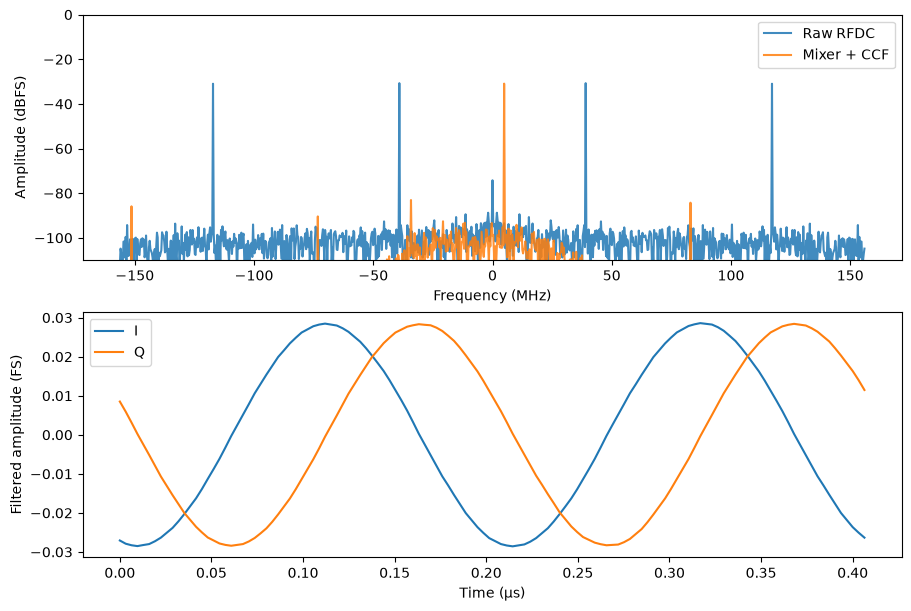

In [4]:
mode = max(captures)
raw, filtered = captures[mode]
fig, axes = plt.subplots(2, 1, figsize=(9, 6), constrained_layout=True)
for samples, label in ((raw, "Raw RFDC"), (filtered, "Mixer + CCF")):
    f, db = spectrum(samples)
    axes[0].plot(f, db, label=label, alpha=.85)
axes[0].set(xlabel="Frequency (MHz)", ylabel="Amplitude (dBFS)", ylim=(-110, 0))
axes[0].legend()
time_us = np.arange(128)/FS*1e6
axes[1].plot(time_us, filtered[:128].real/32768, label="I")
axes[1].plot(time_us, filtered[:128].imag/32768, label="Q")
axes[1].set(xlabel="Time (µs)", ylabel="Filtered amplitude (FS)")
axes[1].legend()
fig.savefig(out/"loopback.png", dpi=160)
plt.show()

In [5]:
inband = [r for r in rows if r["rf_MHz"] == TONES[r["mode"]][0]]
for row in inband:
    assert abs(row["strongest_output_MHz"] - row["expected_MHz"]) <= FS/N/1e6
    assert row["raw_dBFS"] > -60
    assert abs(row["gain_dB"] - row["fir_response_dB"]) < 3
for status in result["blocks"].values():
    assert status["state"] == 5 and status["operational"] == 1
    assert status["events"]["CCSequenceError"] == 0
if result["aligned_trigger"]:
    assert result["blocks"]["mix"]["events"]["CCUpdateError"] == 0
if len(captures) == 4:
    rejection = rows[-2]["gain_dB"] - rows[-1]["gain_dB"]
    print(f"Input-normalized rejection of the second tone: {rejection:.2f} dB")
    assert rows[-1]["raw_dBFS"] > -60 and rejection > 30
    assert result["dac_status"] == 0
print("PASS")

Input-normalized rejection of the second tone: 53.09 dB
PASS
